## 1st assignment: Markov chain in financial mathematics

Starting with Buy: [0.6 0.4]
Starting with Sell: [0.6 0.4]


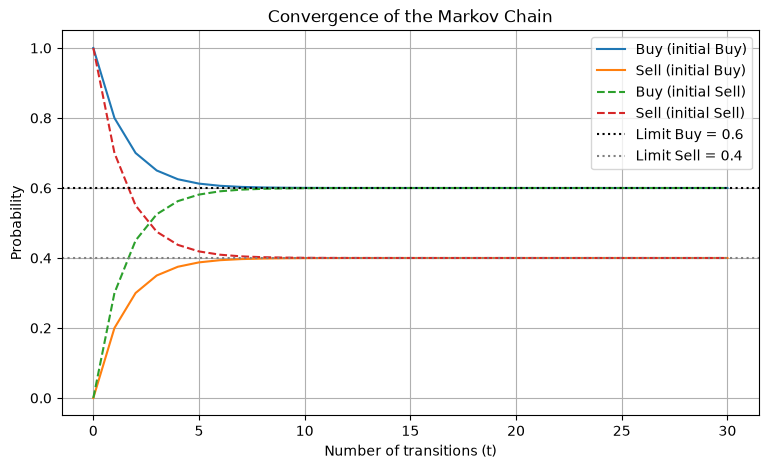

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Transition matrix
A = np.array([
    [0.8, 0.2],
    [0.3, 0.7]
])

# Initial conditions
u0_buy = np.array([1.0, 0.0])
u0_sell = np.array([0.0, 1.0])

# Number of iterations
t_max = 30

# Store the probability distributions
results_buy = [u0_buy]
results_sell = [u0_sell]

# Iteration
for t in range(t_max):
    results_buy.append(results_buy[-1] @ A)
    results_sell.append(results_sell[-1] @ A)

results_buy = np.array(results_buy)
results_sell = np.array(results_sell)

# Display the final distributions
print("Starting with Buy:", results_buy[-1])
print("Starting with Sell:", results_sell[-1])

# Plot convergence
plt.figure(figsize=(9, 5))

plt.plot(results_buy[:, 0], label="Buy (initial Buy)")
plt.plot(results_buy[:, 1], label="Sell (initial Buy)")

plt.plot(results_sell[:, 0], '--', label="Buy (initial Sell)")
plt.plot(results_sell[:, 1], '--', label="Sell (initial Sell)")

plt.axhline(0.6, color='black', linestyle=':', label="Limit Buy = 0.6")
plt.axhline(0.4, color='gray', linestyle=':', label="Limit Sell = 0.4")

plt.xlabel("Number of transitions (t)")
plt.ylabel("Probability")
plt.title("Convergence of the Markov Chain")
plt.legend()
plt.grid()
plt.show()


In [2]:
import numpy as np

A = np.array([
    [0.8, 0.2],
    [0.3, 0.7]
])

# Eigenvalues and right eigenvectors of A
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Eigenvalues:")
print(eigenvalues)

print("Right eigenvectors of A (columns):")
print(eigenvectors)

# Eigenvalues and right eigenvectors of A transpose
eigenvalues_T, eigenvectors_T = np.linalg.eig(A.T)

# Find the eigenvector corresponding to eigenvalue 1
index = np.argmin(np.abs(eigenvalues_T - 1))

stationary = eigenvectors_T[:, index]

# Normalize the eigenvector to obtain probabilities
stationary = stationary / np.sum(stationary)

print("Stationary distribution:")
print(stationary)


Eigenvalues:
[1. +0.j 0.5+0.j]
Right eigenvectors of A (columns):
[[ 0.70710678+0.j -0.5547002 +0.j]
 [ 0.70710678+0.j  0.83205029+0.j]]
Stationary distribution:
[0.6+0.j 0.4+0.j]


### Perron-Frobenius theorem and its connection with the stationary distribution

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Column-stochastic transition matrix
A = np.array([
    [0.8, 0.3],
    [0.2, 0.7]
])

# Initial conditions
u0_buy = np.array([1.0, 0.0])   # Start with Buy
u0_sell = np.array([0.0, 1.0])  # Start with Sell

print("Matrix A:")
print(A)

print("Column sums:", A.sum(axis=0))

Matrix A:
[[0.8 0.3]
 [0.2 0.7]]
Column sums: [1. 1.]


In [6]:
eigenvalues, eigenvectors = np.linalg.eig(A)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors (columns):")
print(eigenvectors)

Eigenvalues:
[1. +0.j 0.5+0.j]

Eigenvectors (columns):
[[ 0.83205029+0.j -0.70710678+0.j]
 [ 0.5547002 +0.j  0.70710678+0.j]]


In [7]:
# Find the eigenvalue closest to 1
index = np.argmin(np.abs(eigenvalues - 1))

# Corresponding eigenvector
u_star = eigenvectors[:, index]

# Normalize so probabilities sum to 1
u_star = u_star / np.sum(u_star)

print("Stationary distribution:")
print(u_star)

Stationary distribution:
[0.6+0.j 0.4+0.j]


In [8]:
print("A @ u_star:")
print(A @ u_star)

print("\nu_star:")
print(u_star)

print("\nStationary condition satisfied:",
      np.allclose(A @ u_star, u_star))

A @ u_star:
[0.6+0.j 0.4+0.j]

u_star:
[0.6+0.j 0.4+0.j]

Stationary condition satisfied: True


In [9]:
# Theoretical limiting matrix
ones = np.ones((1, 2))

A_limit = u_star.reshape(2, 1) @ ones

print("Theoretical limit of A^t:")
print(A_limit)

# Calculate A^t for different values of t
for t in [1, 2, 5, 10, 20, 50]:
    A_power = np.linalg.matrix_power(A, t)

    print(f"\nA^{t}:")
    print(A_power)

Theoretical limit of A^t:
[[0.6+0.j 0.6+0.j]
 [0.4+0.j 0.4+0.j]]

A^1:
[[0.8 0.3]
 [0.2 0.7]]

A^2:
[[0.7  0.45]
 [0.3  0.55]]

A^5:
[[0.6125  0.58125]
 [0.3875  0.41875]]

A^10:
[[0.60039063 0.59941406]
 [0.39960938 0.40058594]]

A^20:
[[0.60000038 0.59999943]
 [0.39999962 0.40000057]]

A^50:
[[0.6 0.6]
 [0.4 0.4]]


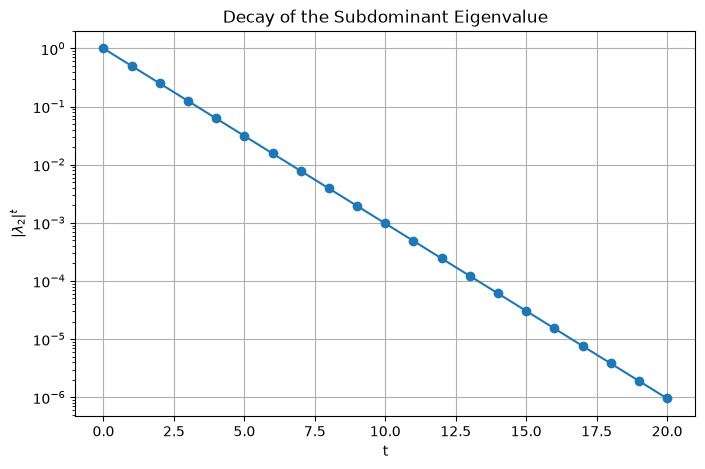

In [10]:
t = np.arange(0, 21)

# Theoretical decay of the transient component
decay = 0.5**t

plt.figure(figsize=(8, 5))
plt.semilogy(t, decay, marker='o')

plt.xlabel("t")
plt.ylabel(r"$|\lambda_2|^t$")
plt.title("Decay of the Subdominant Eigenvalue")
plt.grid(True)
plt.show()


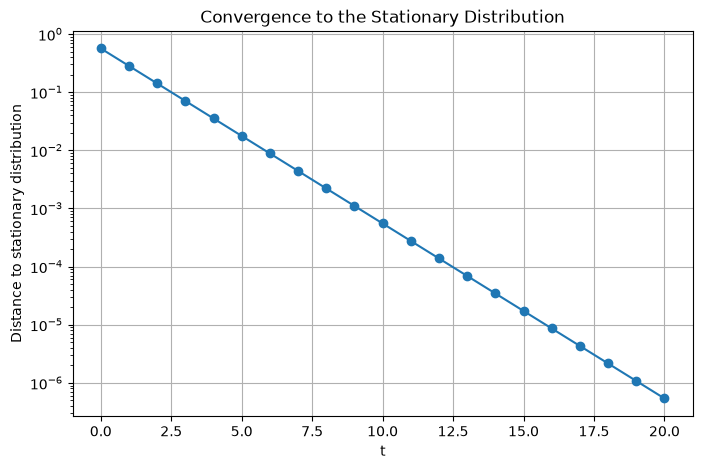

In [11]:
u0 = np.array([1.0, 0.0])  # Starting with Buy

errors = []

for t in range(21):
    u_t = np.linalg.matrix_power(A, t) @ u0

    # Euclidean distance from stationary distribution
    error = np.linalg.norm(u_t - u_star)

    errors.append(error)

plt.figure(figsize=(8, 5))
plt.semilogy(range(21), errors, marker='o')

plt.xlabel("t")
plt.ylabel("Distance to stationary distribution")
plt.title("Convergence to the Stationary Distribution")
plt.grid(True)
plt.show()